# 1 · Aprender a decidir: retorno, información y recompensa

**Lectura acompañada:** capítulo 1, §§1.1–1.3, pp. 13–30 de [Murphy, v5](https://arxiv.org/abs/2412.05265v5). Esta es una explicación propia en español, con ejemplos nuevos; acompaña al original y no lo reproduce íntegramente.

**Al terminar** podrás formular un problema de decisión, calcular un retorno, distinguir estado de observación y comprobar cuándo un cambio de recompensa conserva las preferencias. Necesitas arrays, sumas y probabilidad condicional. Si algo no te resulta familiar, empieza por [los conocimientos previos](../docs/00_conocimientos_previos.md).

**Cómo leer:** ejecuta las celdas de arriba abajo. Antes de cada gráfica, haz una predicción. Después compara lo observado con la explicación siguiente. Los ejemplos usan NumPy y Matplotlib, funcionan en CPU y no requieren archivos del repositorio.

## 1. Preparar nuestro pequeño laboratorio

Usaremos generadores aleatorios locales: volver a ejecutar una simulación con la misma semilla reproduce sus números. Una semilla fija facilita depurar; varias semillas permiten ver cuánto varían las conclusiones. No confundas ambas funciones.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

SEMILLA = 2026
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (8, 3.5), "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 11})


## 2. §1.1 · Una decisión cambia lo que ocurrirá después

Imagina un robot que puede recargar ahora o seguir trabajando. La segunda acción produce una recompensa inmediata, pero puede dejarlo sin energía lejos del cargador. Elegir la acción con mayor premio instantáneo no resuelve necesariamente el problema.

En cada instante distinguimos el estado real $s_t$, la observación $o_t$, la acción $a_t$ y la recompensa $r_t$. Aquí $r_t$ es la recompensa producida al ejecutar $a_t$. Otros textos la llaman $r_{t+1}$: es una convención de índices, no otro algoritmo. La política transforma la información disponible en una distribución de acciones.

Una trayectoria da un retorno:

$$G_t=\sum_{k=0}^{T-t-1}\gamma^k r_{t+k}.$$

El objetivo $J(\pi)=\mathbb E_\pi[G_0]$ promedia trayectorias. Una ejecución afortunada puede tener buen retorno aunque su política tenga mala esperanza. En tareas continuas, el descuento con $\gamma<1$ y recompensas acotadas hace converger la suma; la recompensa media por unidad de tiempo define otro objetivo.

Vamos a comparar recibir 1 ahora con recibir 3 cuatro pasos después. Hay cuatro ceros antes del 3: escribir solo tres cambiaría el problema.


In [2]:
def retorno(recompensas, gamma):
    r = np.asarray(recompensas, dtype=float)
    return float(np.dot(gamma ** np.arange(len(r)), r))

ahora = [1, 0, 0, 0, 0]
despues = [0, 0, 0, 0, 3]
for gamma in [0.5, 0.75, 0.9, 1.0]:
    print(f"gamma={gamma:.2f}: ahora={retorno(ahora, gamma):.3f}, "
          f"después={retorno(despues, gamma):.3f}")
umbral = (1 / 3) ** (1 / 4)
assert np.isclose(retorno(despues, umbral), 1)
print("Umbral de indiferencia:", umbral)


gamma=0.50: ahora=1.000, después=0.188
gamma=0.75: ahora=1.000, después=0.949
gamma=0.90: ahora=1.000, después=1.968
gamma=1.00: ahora=1.000, después=3.000
Umbral de indiferencia: 0.7598356856515925


La comparación se reduce a $3\gamma^4>1$. Por eso un cambio de descuento puede invertir la decisión óptima: es parte de la especificación de la tarea. Con $\gamma=1$ este episodio finito sigue estando bien definido; lo que pierde la garantía general es la suma infinita descontada.

Ahora cambia el retraso. Una recompensa más lejana necesita un descuento más próximo a uno para resultar atractiva.


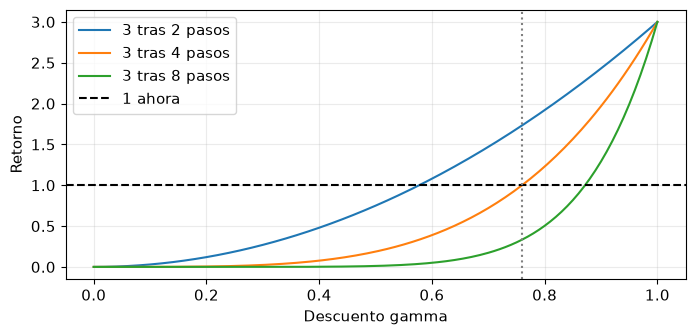

In [3]:
gammas = np.linspace(0, 1, 201)
for retraso in [2, 4, 8]:
    plt.plot(gammas, 3 * gammas**retraso, label=f"3 tras {retraso} pasos")
plt.axhline(1, color="black", linestyle="--", label="1 ahora")
plt.axvline(umbral, color="gray", linestyle=":")
plt.xlabel("Descuento gamma")
plt.ylabel("Retorno")
plt.legend()
plt.show()


## 3. §1.2 · Elegir el modelo antes que el algoritmo

Un MDP supone que el estado utilizado resume la información del pasado relevante para predecir el siguiente estado y recompensa, condicionados a la acción. No afirma que el mundo no tenga historia: afirma que la representación elegida basta para decidir.

En un POMDP vemos observaciones incompletas. Dos historias pueden producir la misma observación actual y requerir acciones distintas. Una política sin memoria no puede distinguirlas. Una política recurrente intenta construir un resumen; una creencia bayesiana es un resumen probabilístico exacto cuando disponemos del modelo apropiado.

| Formulación | Qué cambia | Ejemplo |
|---|---|---|
| Bandit contextual | La acción decide el premio observado; no controla los contextos futuros | Elegir una recomendación para una visita |
| MDP | La acción cambia el estado futuro | Navegar hasta un cargador |
| POMDP | Parte del estado está oculta | Navegar con un sensor ambiguo |
| MDP condicionado por meta | La política recibe el objetivo | Llegar a distintos destinos |
| MDP contextual | Un contexto caracteriza la tarea o dinámica | El mismo robot con diferentes cargas |

La identificación del mejor brazo, la optimización bayesiana y el aprendizaje activo también deciden qué información comprar. Su objetivo puede ser encontrar una buena solución final en vez de acumular recompensa durante la búsqueda. Esa distinción importa al evaluar.


## 4. Memoria: un problema que más entrenamiento no arregla por sí solo

Generamos un bit oculto, lo mostramos una vez y después lo ocultamos. La acción correcta al final es repetirlo. Sin acceso al bit ni a su recuerdo, ambos estados son indistinguibles y cualquier decisión independiente del bit acierta en promedio un 50%.

Si la señal inicial tiene ruido de inversión $\eta$, recordar exactamente esa señal acierta en promedio $1-\eta$. Estamos comparando políticas prescritas: no entrenamos una red para descubrir la memoria.


Ruido=0.0: aciertos=[0.5003 1.    ], IC95 aprox ±[0.0042 0.    ]
Ruido=0.15: aciertos=[0.5003 0.8508], IC95 aprox ±[0.0042 0.0039]
Ruido=0.4: aciertos=[0.5003 0.5962], IC95 aprox ±[0.0042 0.0062]


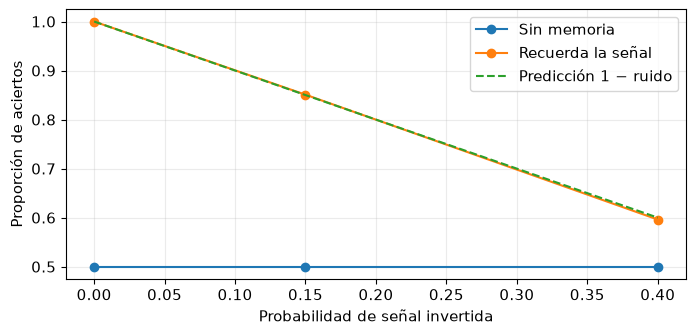

In [4]:
def prueba_memoria(seed, ruido=0.0, episodios=2000):
    rng = np.random.default_rng(seed)
    oculto = rng.integers(0, 2, episodios)
    senal = np.bitwise_xor(oculto, (rng.random(episodios) < ruido).astype(int))
    sin_memoria = rng.integers(0, 2, episodios)
    return np.array([(sin_memoria == oculto).mean(), (senal == oculto).mean()])

ruidos = [0.0, 0.15, 0.4]
medias = []
for ruido in ruidos:
    replicas = np.array([prueba_memoria(SEMILLA + k, ruido) for k in range(20)])
    media = replicas.mean(axis=0)
    error = 1.96 * replicas.std(axis=0, ddof=1) / np.sqrt(len(replicas))
    medias.append(media)
    print(f"Ruido={ruido}: aciertos={media}, IC95 aprox ±{error}")
medias = np.array(medias)
plt.plot(ruidos, medias[:, 0], "o-", label="Sin memoria")
plt.plot(ruidos, medias[:, 1], "o-", label="Recuerda la señal")
plt.plot(ruidos, 1 - np.array(ruidos), "--", label="Predicción 1 − ruido")
plt.xlabel("Probabilidad de señal invertida")
plt.ylabel("Proporción de aciertos")
plt.legend()
plt.show()


Los intervalos son aproximaciones normales entre réplicas, no garantías sobre otras tareas. Con ruido cero, recordar resuelve este entorno perfectamente; con ruido alto, la memoria conserva información poco fiable.

Esto distingue dos incertidumbres del capítulo: no saber **en qué estado estoy** y no saber **cómo funciona el mundo**. La primera puede requerir memoria y filtrado. La segunda requiere aprender parámetros y explorar. Pueden coexistir.

## 5. De una observación a una creencia

Supón que el bit no cambia y el sensor acierta un 80% en cada lectura, independientemente dado el bit. Si $b=P(s=1)$ y observamos $o=1$, Bayes da

$$b'=\frac{0.8b}{0.8b+0.2(1-b)}.$$

El denominador normaliza. Para $o=0$ se intercambian 0.8 y 0.2. La siguiente función actualiza una creencia; no actualiza pesos de una política. En un POMDP con estado que evoluciona haría falta, además, un paso de predicción mediante el modelo de transición.


P(bit=1) tras cada lectura: [0.5    0.8    0.9412 0.8    0.9412]


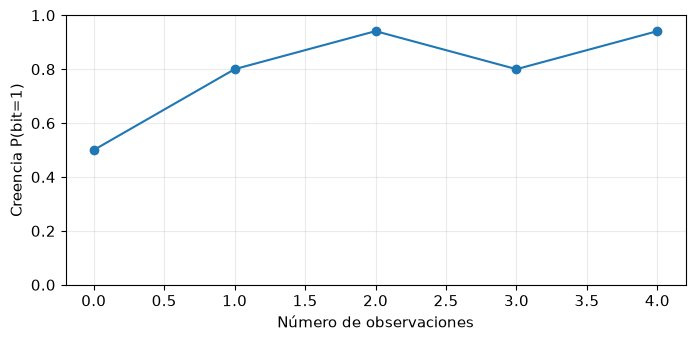

In [5]:
def actualizar_creencia(b, observacion, fiabilidad=0.8):
    l1 = fiabilidad if observacion == 1 else 1 - fiabilidad
    l0 = 1 - fiabilidad if observacion == 1 else fiabilidad
    return b * l1 / (b * l1 + (1 - b) * l0)

lecturas = [1, 1, 0, 1]
creencias = [0.5]
for obs in lecturas:
    creencias.append(actualizar_creencia(creencias[-1], obs))
print("P(bit=1) tras cada lectura:", np.array(creencias))
assert np.isclose(actualizar_creencia(0.5, 1), 0.8)
assert np.isclose(actualizar_creencia(actualizar_creencia(0.5, 1), 0), 0.5)
plt.plot(creencias, "o-")
plt.ylim(0, 1)
plt.xlabel("Número de observaciones")
plt.ylabel("Creencia P(bit=1)")
plt.show()


Una lectura contradictoria reduce la confianza, pero no obliga a olvidar todo lo anterior. La representación adecuada es una probabilidad, no solo la última lectura. Si el sensor estuviese correlacionado en el tiempo, multiplicar estas evidencias como independientes sobreestimaría la confianza.

## 6. §1.3 · Tres maneras de aprender y una pregunta común

Los métodos basados en valores aprenden cuánto conviene actuar; los basados en políticas ajustan directamente cómo actuar; los basados en modelos predicen consecuencias para planificar. Una red neuronal puede participar en cualquiera de las tres familias. Tabular frente a neuronal es otra clasificación.

También importa quién recogió los datos. On-policy aprende sobre la política que los produce. Off-policy permite aprender sobre otra, con condiciones que veremos más adelante. Ninguna de estas etiquetas resuelve automáticamente la exploración: una acción nunca probada sigue siendo desconocida.

La pregunta compartida es qué señal debería mejorar el agente. Si premiamos al robot por acercarse al cargador en cada instante, podría descubrir un bucle que acumule puntos. El problema no sería que optimiza mal, sino que el objetivo escrito permite ese comportamiento.


## 7. Dar pistas sin cambiar el problema: shaping por potencial

Una construcción especial modifica la recompensa mediante

$$r'_t=r_t+\gamma\Phi(s_{t+1})-\Phi(s_t).$$

Al sumar con descuento, los términos intermedios se cancelan:

$$G'_0-G_0=-\Phi(s_0)+\gamma^T\Phi(s_T).$$

Si el potencial terminal es cero, la diferencia solo depende del inicio. Por tanto, desde ese inicio conserva la ordenación de trayectorias y de políticas. Esa condición terminal no es decorativa: vamos a comprobarla con rutas de distinta longitud.


In [6]:
gamma = 0.9
phi = {"inicio": -2.0, "pasillo": -1.0, "desvio": -1.5, "meta": 0.0}
rutas = [
    (["inicio", "pasillo", "meta"], [0, 1]),
    (["inicio", "desvio", "pasillo", "meta"], [0, 0, 1]),
]
for estados, recompensas in rutas:
    modificadas = [r + gamma * phi[sn] - phi[s]
                   for s, sn, r in zip(estados[:-1], estados[1:], recompensas)]
    original = retorno(recompensas, gamma)
    nuevo = retorno(modificadas, gamma)
    assert np.isclose(nuevo - original, -phi["inicio"])
    print(f"Ruta de {len(recompensas)} pasos: {original:.3f} → {nuevo:.3f}")


Ruta de 2 pasos: 0.900 → 2.900
Ruta de 3 pasos: 0.810 → 2.810


El shaping cambia las recompensas intermedias y puede facilitar el aprendizaje, aunque en este ejemplo aún no hemos entrenado nada. La invariancia del objetivo no garantiza igual velocidad de aprendizaje con cualquier algoritmo y representación.

## 8. Ejercicio: romper una condición y diagnosticar el resultado

**Predice primero.** Pon potencial 10 en la meta. ¿Sigue siendo constante la diferencia para dos rutas de distinta longitud? Después cambia el retraso y la recompensa de la sección 2 para diseñar una preferencia diferente.


In [7]:
potencial_terminal = 10.0  # Prueba también 0.0.
for estados, recompensas in rutas:
    phi_variante = dict(phi, meta=potencial_terminal)
    nuevas = [r + gamma * phi_variante[sn] - phi_variante[s]
              for s, sn, r in zip(estados[:-1], estados[1:], recompensas)]
    diferencia = retorno(nuevas, gamma) - retorno(recompensas, gamma)
    predicha = -phi_variante["inicio"] + gamma**len(recompensas) * potencial_terminal
    assert np.isclose(diferencia, predicha)
    print("Duración:", len(recompensas), "Cambio de retorno:", round(diferencia, 4))


Duración: 2 Cambio de retorno: 10.1
Duración: 3 Cambio de retorno: 9.29


<details>
<summary>Solución orientativa y preguntas para discutir</summary>

Con potencial terminal 10, el término final pesa 8.1 o 7.29 según la duración. La diferencia ya no es una constante común. El fallo está en aplicar una conclusión sin su condición terminal. Esto no significa que todas las preferencias cambien necesariamente: significa que la invariancia ya no está garantizada.

En la tarea de memoria, aumentar las muestras no permite recuperar una señal que nunca llega a la política. Un cambio útil sería ampliar su entrada o su estado interno.

Para el grupo: formula un problema de tu trabajo indicando observación, acción, recompensa, horizonte y datos disponibles. Justifica qué información necesitarías para que el estado fuese suficiente.

</details>

## 9. Lo que nos llevamos al capítulo 2

Ya podemos separar objetivo, información y aprendizaje. El siguiente paso es asignar valor a las consecuencias de actuar y propagar ese valor hacia atrás. Esa operación será Bellman.

Los ejemplos de este cuaderno son cálculos y políticas prescritas; no demuestran que un algoritmo neuronal vaya a aprender las representaciones necesarias. Para la ejecución de referencia del proyecto y sus veinte réplicas, consulta [el resumen del capítulo](../docs/01_introduccion.md) y [los resultados](../resultados/INFORME.md).

**Fuente y atribución:** explicación adaptada de Kevin P. Murphy, *Reinforcement Learning: An Overview*, v5, [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Ejemplos y código propios de esta guía; no implican respaldo del autor.
